In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Memuat dataset (sama seperti kodemu)
#df_sales = pd.read_csv("../datasets/01_ecommerce_sales_eda.csv")
print("Dimensi dataset:", df_sales.shape)
display(df_sales.head())

# 2. Cek struktur dan data kosong
print(df_sales.dtypes)
print(df_sales.isnull().sum())

# 3. Statistik sesuai skala
print("Nominal  - frekuensi payment_method:")
print(df_sales['payment_method'].value_counts())          # nominal: frekuensi & modus

print("\nOrdinal  - frekuensi customer_satisfaction:")
print(df_sales['customer_satisfaction'].value_counts())   # ordinal: modus & median

print("\nRasio    - total_amount_k:")
print(df_sales['total_amount_k'].describe())              # rasio: semua operasi boleh
print("Mean:", df_sales['total_amount_k'].mean(), "| Median:", df_sales['total_amount_k'].median())

# 4. Encoding (sama seperti modul)
df_sales['satisfaction_encoded'] = df_sales['customer_satisfaction'].map({'Low': 1, 'Medium': 2, 'High': 3})
df_encoded = pd.get_dummies(df_sales, columns=['payment_method'], prefix='pay')

# 5. Hubungan ordinal dan rasio: median belanja per tingkat kepuasan
print(df_sales.groupby('customer_satisfaction')['total_amount_k'].median())

Dimensi dataset: (150, 11)


,transaction_id,customer_age,gender,category,payment_method,items_count,price_per_unit_k,discount_pct,total_amount_k,customer_satisfaction,delivery_days
0,TRX_0001,56,Wanita,Kebutuhan Pokok,Bank Transfer,5,252.6,5,1199.85,Medium,1
1,TRX_0002,46,Wanita,Buku,E-Wallet,8,316.8,15,2154.24,High,4
2,TRX_0003,32,Wanita,Fashion,Bank Transfer,4,197.1,0,788.40,Medium,6
3,TRX_0004,25,Wanita,Elektronik,E-Wallet,8,242.0,0,1936.00,High,1
4,TRX_0005,38,Wanita,Elektronik,Bank Transfer,2,378.8,15,643.96,High,2


transaction_id            object
customer_age               int64
gender                    object
category                  object
payment_method            object
items_count                int64
price_per_unit_k         float64
discount_pct               int64
total_amount_k           float64
customer_satisfaction     object
delivery_days              int64
dtype: object
transaction_id           0
customer_age             0
gender                   0
category                 0
payment_method           0
items_count              0
price_per_unit_k         0
discount_pct             0
total_amount_k           0
customer_satisfaction    0
delivery_days            0
dtype: int64
Nominal  - frekuensi payment_method:
payment_method
E-Wallet         58
Bank Transfer    42
Credit Card      29
COD              21
Name: count, dtype: int64

Ordinal  - frekuensi customer_satisfaction:
customer_satisfaction
Medium    59
High      54
Low       37
Name: count, dtype: int64

Rasio    - total_amoun

In [11]:
from google.colab import data_table

# Mengaktifkan formatter tabel data interaktif bawaan Google Colab
data_table.enable_dataframe_formatter()

# Menampilkan data df_sales secara interaktif
display(df_sales)

,transaction_id,customer_age,gender,category,payment_method,items_count,price_per_unit_k,discount_pct,total_amount_k,customer_satisfaction,delivery_days,satisfaction_encoded
0,TRX_0001,56,Wanita,Kebutuhan Pokok,Bank Transfer,5,252.6,5,1199.85,Medium,1,2
1,TRX_0002,46,Wanita,Buku,E-Wallet,8,316.8,15,2154.24,High,4,3
2,TRX_0003,32,Wanita,Fashion,Bank Transfer,4,197.1,0,788.40,Medium,6,2
3,TRX_0004,25,Wanita,Elektronik,E-Wallet,8,242.0,0,1936.00,High,1,3
4,TRX_0005,38,Wanita,Elektronik,Bank Transfer,2,378.8,15,643.96,High,2,3
...,...,...,...,...,...,...,...,...,...,...,...,...
145,TRX_0146,45,Pria,Kebutuhan Pokok,E-Wallet,8,184.2,15,1252.56,High,1,3
146,TRX_0147,19,Wanita,Kebutuhan Pokok,E-Wallet,1,414.2,0,414.20,High,2,3
147,TRX_0148,59,Pria,Fashion,COD,3,73.1,20,175.44,Low,1,1
148,TRX_0149,23,Wanita,Elektronik,Credit Card,4,426.3,5,1619.94,High,1,3


In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Memuat dataset transaksi
# [Google Colab] Jika menjalankan di Colab, gunakan tautan direct raw GitHub berikut:
url_01_ecommerce_sales_eda = "https://raw.githubusercontent.com/rdwnilyas-coder/statistika-komputasi-unjani/refs/heads/main/datasets/01_ecommerce_sales_eda.csv"
df_sales = pd.read_csv(url_01_ecommerce_sales_eda)
# df_sales = pd.read_csv("../datasets/01_ecommerce_sales_eda.csv")
print("Dimensi dataset:", df_sales.shape)
display(df_sales.head())

Dimensi dataset: (150, 11)


,transaction_id,customer_age,gender,category,payment_method,items_count,price_per_unit_k,discount_pct,total_amount_k,customer_satisfaction,delivery_days
0,TRX_0001,56,Wanita,Kebutuhan Pokok,Bank Transfer,5,252.6,5,1199.85,Medium,1
1,TRX_0002,46,Wanita,Buku,E-Wallet,8,316.8,15,2154.24,High,4
2,TRX_0003,32,Wanita,Fashion,Bank Transfer,4,197.1,0,788.40,Medium,6
3,TRX_0004,25,Wanita,Elektronik,E-Wallet,8,242.0,0,1936.00,High,1
4,TRX_0005,38,Wanita,Elektronik,Bank Transfer,2,378.8,15,643.96,High,2


In [19]:
df_encoded = pd.get_dummies(df_sales, columns=['payment_method'],
                            prefix='pay', drop_first=False, dtype=int)

pay_cols = [c for c in df_encoded.columns if c.startswith('pay_')]
display(df_encoded[['transaction_id', 'payment_method'] + pay_cols].head() if 'payment_method' in df_encoded else df_encoded[['transaction_id'] + pay_cols].head())

# Verifikasi: tiap baris harus berjumlah tepat 1
print("Semua baris punya tepat satu 1:", (df_encoded[pay_cols].sum(axis=1) == 1).all())

,transaction_id,pay_Bank Transfer,pay_COD,pay_Credit Card,pay_E-Wallet
0,TRX_0001,1,0,0,0
1,TRX_0002,0,0,0,1
2,TRX_0003,1,0,0,0
3,TRX_0004,0,0,0,1
4,TRX_0005,1,0,0,0


Semua baris punya tepat satu 1: True


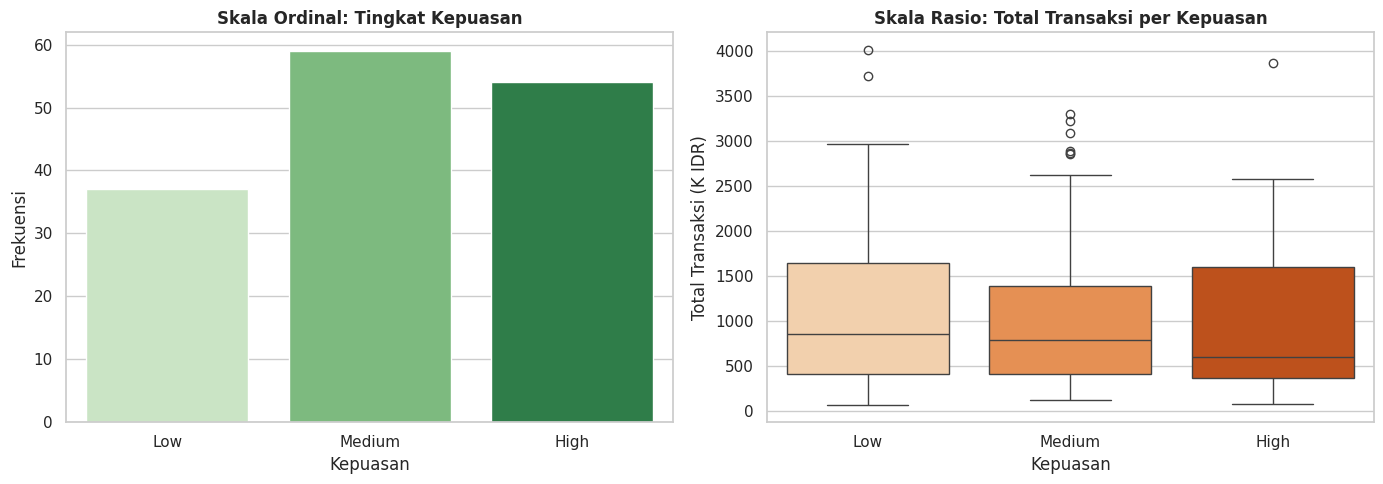

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ordinal: countplot dengan urutan yang benar
sns.countplot(data=df_sales, x='customer_satisfaction', order=['Low', 'Medium', 'High'], hue='customer_satisfaction', legend=False, palette='Greens', ax=axes[0])
axes[0].set_title('Skala Ordinal: Tingkat Kepuasan', fontweight='bold')
axes[0].set_xlabel('Kepuasan')
axes[0].set_ylabel('Frekuensi')

# Rasio: boxplot per kepuasan (menampilkan median dan outlier)
sns.boxplot(data=df_sales, x='customer_satisfaction', y='total_amount_k', order=['Low', 'Medium', 'High'], hue='customer_satisfaction', legend=False, palette='Oranges', ax=axes[1])
axes[1].set_title('Skala Rasio: Total Transaksi per Kepuasan', fontweight='bold')
axes[1].set_xlabel('Kepuasan')
axes[1].set_ylabel('Total Transaksi (K IDR)')

plt.tight_layout()
plt.show()